# Pork rasher defect detection: Colab workflow

Thin notebook: all logic lives in the `porkrasher` package. Use a GPU runtime (Runtime > Change runtime type > T4 GPU).


In [3]:
# EDIT THESE TWO
REPO_URL = "https://github.com/Nicholas-2305/MMA3001-Project-Nicholas-Caciolo-34988858.git"
ZIP_PATH = "/content/drive/MyDrive/2026 - Third Year/Semester 2/MMA3001 - Numerical Models and Machine Learning/Project MEAT/Pork Rasher Error-Packaging-.v4i.yolo26.zip"


In [4]:
!git clone $REPO_URL repo
%cd repo
!pip install -q -e .


Cloning into 'repo'...
remote: Enumerating objects: 51, done.
remote: Counting objects: 100% (51/51), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 51 (delta 5), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (51/51), 1.51 MiB | 19.36 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/content/repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 10.5 MB/s eta 0:00:00
  Building editable for porkrasher (pyproject.toml) ... done


In [5]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [7]:
import sys
sys.path.insert(0, "/content/repo/src")

In [8]:
from porkrasher.data import extract_dataset, write_data_yaml
root = extract_dataset(ZIP_PATH, '/content/dataset', overwrite=True)
data_yaml = write_data_yaml(root)
print(root, data_yaml)


/content/dataset /content/dataset/data_fixed.yaml


In [9]:
!python -m porkrasher.data --root /content/dataset


Instances per class
class               train   valid    test   total
loose-meat             66       3       3      72
packaging-error      1712      34      23    1769
twisted-meat           72       3       4      79
unsealed             1055      81      49    1185
wrinkle                18       0       0      18
train: 3349 images, 684 background, 2923 instances
valid: 120 images, 14 background, 121 instances
test: 80 images, 12 background, 79 instances

Source frames shared between splits (possible leakage)
  train & valid: 8
  train & test: 4
  valid & test: 1

Training annotation size (fraction of image area)
  packaging-error   n= 1712 median=0.0036 min=0.0004 max=0.0981
  unsealed          n= 1055 median=0.1086 min=0.0042 max=0.3025
  wrinkle           n=   18 median=0.0095 min=0.0035 max=0.0249
  twisted-meat      n=   72 median=0.0384 min=0.0108 max=0.1013
  loose-meat        n=   66 median=0.0543 min=0.0088 max=0.1456


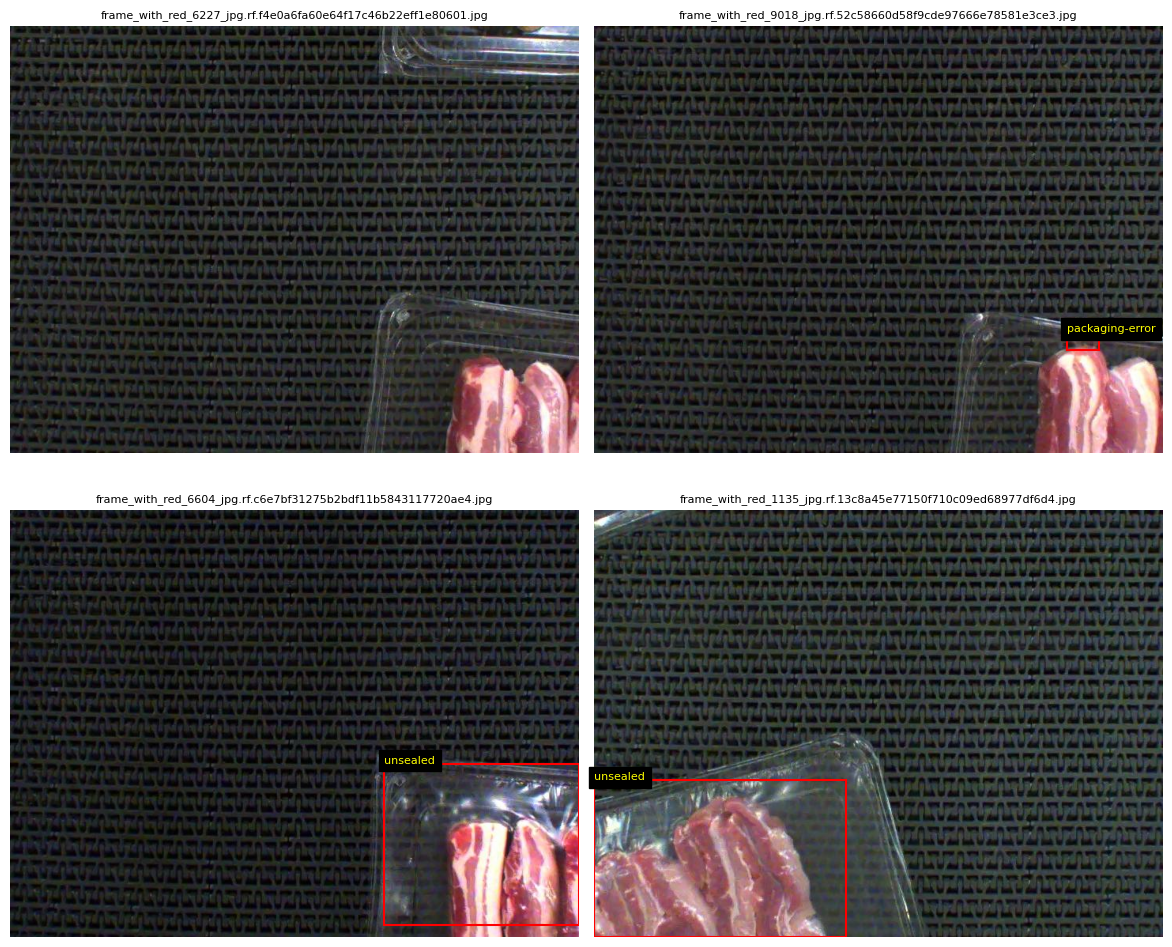

In [10]:
from porkrasher.visualise import plot_samples
fig = plot_samples('/content/dataset/train/images', '/content/dataset/train/labels', n=4, seed=0)


## Training (selected model: YOLOv8n; comparison: YOLOv8s)

In [11]:
from porkrasher.train import train
best_n = train('yolov8n.pt', data_yaml, epochs=100, name='yolov8n_100ep')
print(best_n)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed

In [ ]:
best_s = train('yolov8s.pt', data_yaml, epochs=100, name='yolov8s_100ep')
print(best_s)


## Validation split (use for model selection)

In [14]:
from porkrasher.evaluate import evaluate, format_results_table, format_per_class_table
res_n = evaluate(best_n, data_yaml, split='val', out_json='results/yolov8n_val.json')
results = {'yolov8n': res_n}
print(format_results_table(results))
print(format_per_class_table(results, 'map50'))


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2334.8±814.5 MB/s, size: 65.6 KB)
val: Scanning /content/dataset/valid/labels.cache... 120 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 120/120 38.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.8it/s 2.9s
                   all        120        121      0.578      0.592      0.539      0.327
            loose-meat          3          3      0.237      0.333      0.223      0.109
       packaging-error         23         34       0.26      0.516      0.336      0.104
          twisted-meat          3          3          1      0.594      0.665      0.466
              unsealed         81         81      0.817      0.926       0.93      0.628
Speed: 3.2ms preprocess, 4.6ms inference, 0.0ms l

## Test split

**Warning:** run this once, on the final chosen model only. Do not tune anything after seeing these numbers.

In [ ]:
res_test = evaluate(best_n, data_yaml, split='test', out_json='results/yolov8n_test.json')
print(format_results_table({'yolov8n': res_test}))


In [ ]:
from porkrasher.evaluate import benchmark_inference
from porkrasher.data import list_images
print(benchmark_inference(best_n, list_images('/content/dataset/test/images')))


Copy `best.pt` for both models to Drive so they survive the session.

In [ ]:
!cp {best_n} /content/drive/MyDrive/yolov8n_best.pt
!cp {best_s} /content/drive/MyDrive/yolov8s_best.pt
